# AI Companion Dependency Analysis and Risk Prediction

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\Vaishnavi Urankar\Downloads\ai_companion_dependency_dataset.csv")

In [15]:
df.dtypes

user_id                                    str
age                                      int64
gender                                     str
occupation_status                          str
education_level                            str
income_level                               str
relationship_status                        str
living_situation                           str
country_region                             str
ai_chatbot_platform                        str
primary_use_case                           str
daily_ai_chat_hours                    float64
human_social_interaction_hours         float64
social_media_hours_daily               float64
screen_time_total_hours                float64
number_of_close_friends                  int64
loneliness_score                       float64
emotional_attachment_score             float64
real_relationship_satisfaction         float64
prefers_ai_over_humans                     str
sleep_hours                            float64
sleep_quality

In [6]:
df.head()

,user_id,age,gender,occupation_status,education_level,income_level,relationship_status,living_situation,country_region,ai_chatbot_platform,...,sleep_hours,sleep_quality_score,exercise_hours_weekly,anxiety_score,depression_score,stress_score,self_esteem_score,academic_or_work_performance_change,therapy_attendance,dependency_risk_label
0,U0001,21,Male,Employed Full-Time,High School,Lower-Middle,In a Relationship,With Partner,South America,ChatGPT,...,7.3,9.1,3.3,3.5,3.0,1.0,9.5,Improved,No,Low
1,U0002,34,Male,Student,Graduate,Upper-Middle,Single,Alone,North America,Character.AI,...,7.5,3.5,0.9,4.6,2.4,5.2,4.7,Same,No,Moderate
2,U0003,43,Male,Employed Full-Time,Graduate,Low,Single,Alone,Europe,Character.AI,...,6.8,8.3,7.6,1.0,1.0,3.2,7.2,Improved,No,Low
3,U0004,29,Non-binary,Employed Full-Time,Graduate,Low,Single,With Family,Asia,ChatGPT,...,9.5,8.9,7.4,2.7,1.5,2.6,9.0,Improved,No,Low
4,U0005,25,Female,Student,Graduate,Upper-Middle,In a Relationship,With Roommates,South America,ChatGPT,...,8.5,10.0,6.5,1.0,1.0,1.0,9.9,Improved,No,Low


In [7]:
df.shape

(1000, 30)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   user_id                              1000 non-null   str    
 1   age                                  1000 non-null   int64  
 2   gender                               1000 non-null   str    
 3   occupation_status                    1000 non-null   str    
 4   education_level                      1000 non-null   str    
 5   income_level                         1000 non-null   str    
 6   relationship_status                  1000 non-null   str    
 7   living_situation                     1000 non-null   str    
 8   country_region                       1000 non-null   str    
 9   ai_chatbot_platform                  1000 non-null   str    
 10  primary_use_case                     1000 non-null   str    
 11  daily_ai_chat_hours                  1000 

In [9]:
df.isnull().sum()

user_id                                0
age                                    0
gender                                 0
occupation_status                      0
education_level                        0
income_level                           0
relationship_status                    0
living_situation                       0
country_region                         0
ai_chatbot_platform                    0
primary_use_case                       0
daily_ai_chat_hours                    0
human_social_interaction_hours         0
social_media_hours_daily               0
screen_time_total_hours                0
number_of_close_friends                0
loneliness_score                       0
emotional_attachment_score             0
real_relationship_satisfaction         0
prefers_ai_over_humans                 0
sleep_hours                            0
sleep_quality_score                    0
exercise_hours_weekly                  0
anxiety_score                          0
depression_score

In [10]:
df = df.dropna()

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
from sklearn.preprocessing import LabelEncoder

In [13]:
le = LabelEncoder()

In [17]:
cat_cols

Index(['user_id', 'gender', 'occupation_status', 'education_level',
       'income_level', 'relationship_status', 'living_situation',
       'country_region', 'ai_chatbot_platform', 'primary_use_case',
       'prefers_ai_over_humans', 'academic_or_work_performance_change',
       'therapy_attendance', 'dependency_risk_label'],
      dtype='str')

In [18]:
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [19]:
df

,user_id,age,gender,occupation_status,education_level,income_level,relationship_status,living_situation,country_region,ai_chatbot_platform,...,sleep_hours,sleep_quality_score,exercise_hours_weekly,anxiety_score,depression_score,stress_score,self_esteem_score,academic_or_work_performance_change,therapy_attendance,dependency_risk_label
0,0,21,1,0,1,2,1,2,5,1,...,7.3,9.1,3.3,3.5,3.0,1.0,9.5,1,0,1
1,1,34,1,3,0,3,3,0,3,0,...,7.5,3.5,0.9,4.6,2.4,5.2,4.7,2,0,2
2,2,43,1,0,0,1,3,0,2,0,...,6.8,8.3,7.6,1.0,1.0,3.2,7.2,1,0,1
3,3,29,2,0,0,1,3,1,1,1,...,9.5,8.9,7.4,2.7,1.5,2.6,9.0,1,0,1
4,4,25,0,3,0,3,1,3,5,1,...,8.5,10.0,6.5,1.0,1.0,1.0,9.9,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,35,0,3,3,1,1,2,1,0,...,7.4,4.7,5.1,5.6,3.4,7.2,4.8,0,0,1
996,996,19,1,3,3,2,2,1,3,2,...,7.3,7.6,6.2,2.7,6.6,5.5,10.0,1,1,2
997,997,24,1,1,1,2,3,1,5,0,...,7.1,10.0,6.0,3.2,3.8,3.3,7.9,1,0,1
998,998,24,1,1,1,2,3,1,2,1,...,7.0,5.8,5.0,3.4,5.8,4.9,6.1,2,0,1


# EXPLORATORY DATA ANALYSIS (EDA)

# Dependency Risk Pie Chart

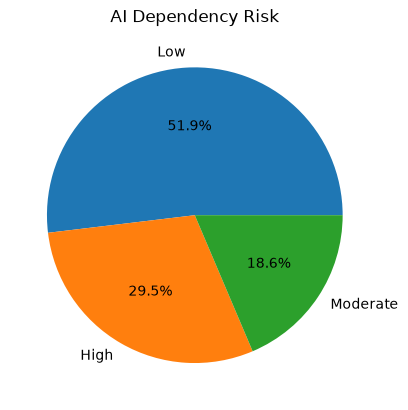

In [11]:
df['dependency_risk_label'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("AI Dependency Risk")
plt.ylabel("")
plt.show()

# AI Platform Bar Chart

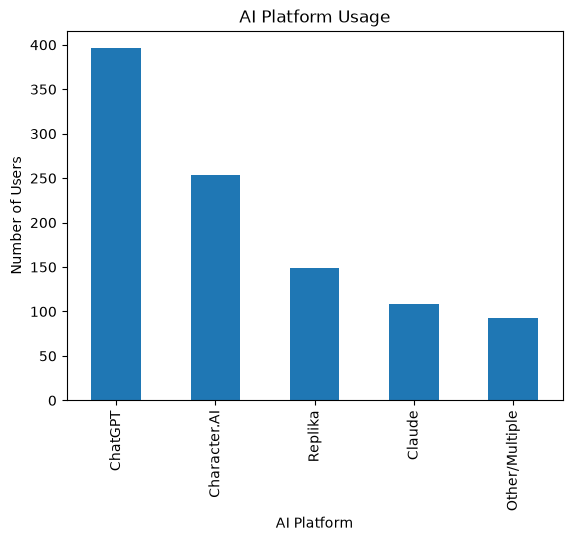

In [13]:
df['ai_chatbot_platform'].value_counts().plot(kind='bar')
plt.title("AI Platform Usage")
plt.xlabel("AI Platform")
plt.ylabel("Number of Users")
plt.show()

# Daily AI Chat Hours Histogram

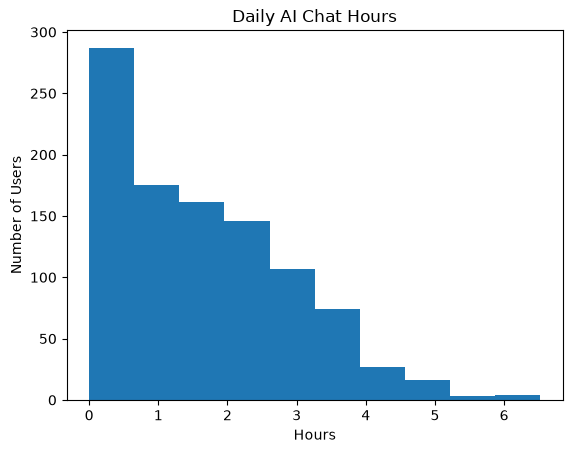

In [14]:
plt.hist(df['daily_ai_chat_hours'], bins=10)
plt.title("Daily AI Chat Hours")
plt.xlabel("Hours")
plt.ylabel("Number of Users")
plt.show()

# Dependency Risk Bar Chart

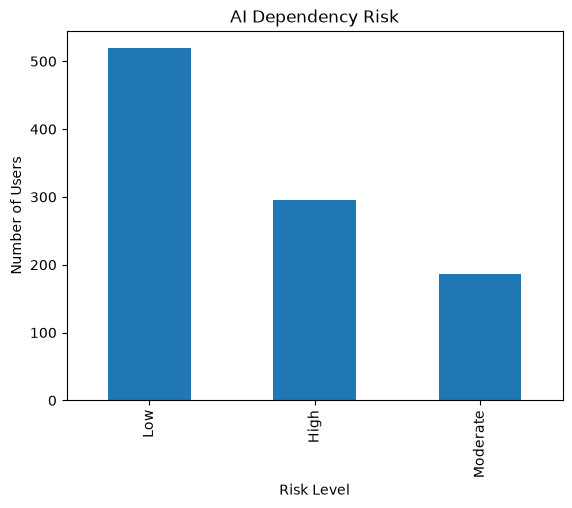

In [15]:
df['dependency_risk_label'].value_counts().plot(kind='bar')
plt.title("AI Dependency Risk")
plt.xlabel("Risk Level")
plt.ylabel("Number of Users")
plt.show()

# Correlation Heatmap

In [16]:
num = df.select_dtypes(include='number')

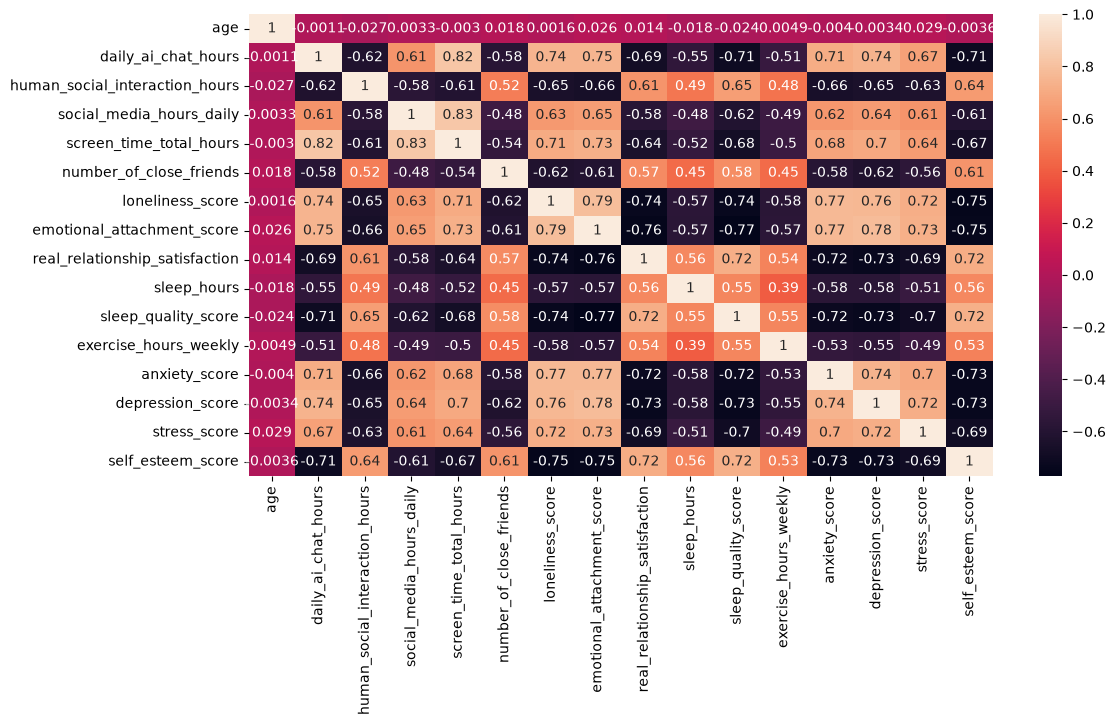

In [17]:
plt.figure(figsize=(12,6))
sns.heatmap(num.corr(), annot=True)
plt.show()

# Insight:
1. Pie Chart – AI Dependency Risk
The pie chart shows the distribution of users among Low, Moderate and High AI dependency-risk categories. It helps understand the overall dependency pattern in the dataset.
2. Bar Chart – AI Platform Usage
The bar chart compares the number of users using different AI platforms. It helps identify the most commonly used AI platforms among the users.
3. Histogram – Daily AI Chat Hours
The histogram shows how daily AI chat hours are distributed among users. It helps understand the typical amount of time users spend interacting with AI companions.
4. Bar Chart – AI Dependency Risk
The bar chart compares the number of users in each dependency-risk category. It makes it easier to identify which risk category has the highest number of users.
5. Heatmap – Correlation Analysis
The heatmap shows the relationships between numerical variables such as daily AI chat hours, human social interaction, loneliness, emotional attachment, sleep, anxiety, depression and stress. It helps identify positive and negative relationships between these factors and understand which variables may be associated with AI dependency.

# Feature Selection

In [19]:
x = df[['age','daily_ai_chat_hours','human_social_interaction_hours',
        'loneliness_score','emotional_attachment_score',
        'sleep_hours','anxiety_score','depression_score','stress_score']]

In [20]:
y = df['dependency_risk_label']

# Encode

In [21]:
y = y.map({'Low':0,'Moderate':1,'High':2})

In [22]:
y.value_counts()

dependency_risk_label
0    519
2    295
1    186
Name: count, dtype: int64

In [23]:
x.head()

,age,daily_ai_chat_hours,human_social_interaction_hours,loneliness_score,emotional_attachment_score,sleep_hours,anxiety_score,depression_score,stress_score
0,21,0.00,6.60,4.5,2.0,7.3,3.5,3.0,1.0
1,34,2.36,2.88,5.9,2.3,7.5,4.6,2.4,5.2
2,43,0.07,4.56,1.1,1.0,6.8,1.0,1.0,3.2
3,29,0.44,5.66,3.2,1.8,9.5,2.7,1.5,2.6
4,25,0.00,6.56,1.0,1.0,8.5,1.0,1.0,1.0


# Train-Test Split

In [25]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y)

# Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)

Train the model

In [27]:
lr.fit(x_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

# Prediction

In [28]:
pred_lr = lr.predict(x_test)

In [29]:
pred_lr[:10]

array([2, 0, 1, 2, 2, 2, 0, 1, 1, 2])

# Accuracy

In [30]:
from sklearn.metrics import accuracy_score

In [31]:
accuracy_score(y_test,pred_lr)

0.835

# Confusion Matrix

In [33]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,pred_lr)

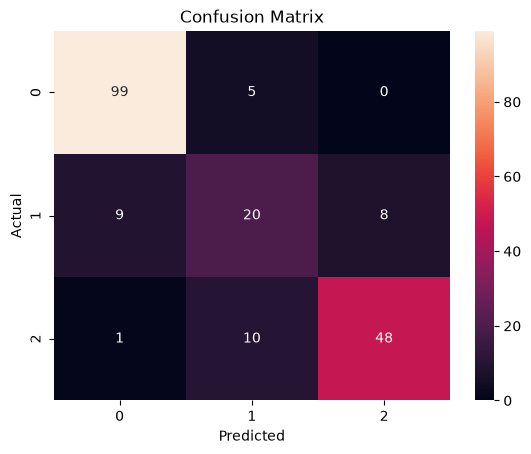

In [34]:
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Explanation:

The confusion matrix shows how correctly the model classified users into Low, Moderate and High dependency-risk categories.

# Classification Report

In [35]:
from sklearn.metrics import classification_report
print(classification_report(y_test,pred_lr))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       104
           1       0.57      0.54      0.56        37
           2       0.86      0.81      0.83        59

    accuracy                           0.83       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.83      0.83      0.83       200



# Report:

The classification report provides precision, recall and F1-score for each dependency-risk category.

# Actual vs Predicted

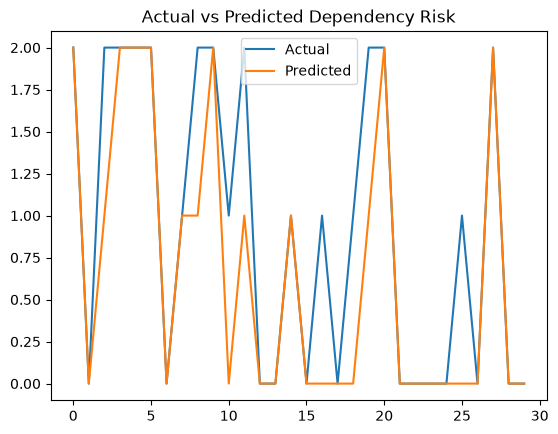

In [36]:
plt.plot(y_test.values[:30],label="Actual")
plt.plot(pred_lr[:30],label="Predicted")
plt.legend()
plt.title("Actual vs Predicted Dependency Risk")
plt.show()

# Actual vs Predicted Insight: 
The graph compares the actual dependency-risk categories with the categories predicted by the Logistic Regression model. The predicted values generally follow the actual values, although some differences can be observed, particularly for certain Moderate-risk cases.